# 05 — LightGBM development and hyperparameter tuning

**The tuned 61-feature LightGBM is the selected daily model from this experiment series.** It combines the median-relative log target with three explicit ratios, larger historical training samples and a wider tuning search. Its published development log RMSE is **0.46357**, with **34.88% WAPE**.

This notebook explains how that result was reached. It covers compact versus expanded features, squared-error versus Huber loss, ridge–tree blends, the ratio additions, sample expansion, eight tuning configurations and linear trees. It finishes **Checkpoint 3**. Tuned CatBoost and XGBoost follow at Checkpoint 4.

Saved experiment tables reproduce the completed studies. A worked 2022 fold below reruns the full eight-configuration search on historical 2021 validation, then refits the selected configuration on up to one million earlier rows. Its score is a fresh refit, reported separately from the published ranking. The original compact models are also reconstructed from saved parameters and verified against their annual metrics.

Run from this repository with its EDA and model dependencies. The worked fit takes several minutes. All tables and figures are embedded. Source data and historical experiment artifacts are read in place.

In [1]:
from pathlib import Path
import sys
import tempfile
import json
import hashlib
import importlib.metadata
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "blackrock_data").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "blackrock_data"
RESULTS = PROJECT_ROOT / "outputs"
work = tempfile.TemporaryDirectory(prefix="auction-master-")
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("SET memory_limit='2GB'")
con.execute("SET temp_directory=?", [work.name])
AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
SECTOR = str(DATA / "sector/sector_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")
def sql(query, params=None):
    return con.execute(query, params or []).df()
def saved(relative):
    return pd.read_csv(RESULTS / relative)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110})
display(pd.DataFrame({"package": ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"],
                      "version": [importlib.metadata.version(p) for p in ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"]]}))
import gc
import os
import lightgbm as lgb
from notebooks.modeling_utils import fit_preprocessor, apply_preprocessor, forecast_metrics
warnings.filterwarnings('ignore', message='X does not have valid feature names')
EDA = RESULTS / 'eda'
ORIGINAL = EDA / '16_nonlinear_challengers'
VERIFIED = RESULTS / 'reproduction/03_compact_nonlinear'
TUNING = EDA / '16a_lightgbm_improvements'
FROZEN = json.loads((EDA / '09_global_finalists/frozen_global_benchmark.json').read_text())
RIDGE = FROZEN['champion']
CONTROL = 'lgbm_58_control'
RATIOS = 'lgbm_61_ratios'
LARGE = 'lgbm_61_ratios_large'
TUNED = 'lgbm_61_ratios_large_tuned'
LINEAR = 'lgbm_61_ratios_large_linear'
DEV = [2022, 2023, 2024]
NAMES = {RIDGE:'Frozen ridge', CONTROL:'A · 58-feature control', RATIOS:'B · add ratios',
         LARGE:'C · more training rows', TUNED:'D · wider tuning', LINEAR:'E · linear trees'}
def study(folder, filename):return pd.read_csv(folder / filename)
print(f'Execution LightGBM {lgb.__version__}. Published tuning run recorded LightGBM 4.7.0.')

,package,version
0,duckdb,1.5.6
1,numpy,2.4.6
2,pandas,3.1.1
3,matplotlib,3.11.2
4,seaborn,0.13.2


Execution LightGBM 4.6.0. Published tuning run recorded LightGBM 4.7.0.


## Why a tree model can improve on ridge

Ridge gives a linear response in the transformed inputs. LightGBM builds a sum of trees, with each tree correcting the current model's remaining errors. Splits can capture thresholds and interactions, such as a recent volume surprise behaving differently on month-end days.

We retain the same target,

$$r_t=\log(1+A_t)-\log(1+M_{20,t}),$$

and reconstruct auction shares after predicting the residual. This lets us compare modelling methods on the same outcome and information set. More leaves increase flexibility. Minimum leaf size, shrinkage, row and feature sampling, and penalties control that flexibility. Early stopping chooses a useful number of trees using an earlier validation year.

| Candidate choice | Question it tests |
| --- | --- |
| 58 vs 99 source features | Does the broader set add useful nonlinear signal? |
| Squared-error loss | Does minimising residual squared error improve log RMSE? |
| Huber loss | Does reducing the influence of large residuals help overall accuracy? |
| 50/50 ridge–tree blend in log space | Do the models make complementary errors? |
| Explicit volume ratios | Can a tree use relative activity more directly? |
| Larger samples | Is limited training data constraining the tree fit? |
| Wider tuning | Can different complexity and regularisation settings improve generalisation? |
| Linear trees | Do linear regressions within leaves capture the remaining structure? |

## Chronological fitting and evaluation

The five-year refit, prior-close feature timing, median-relative target and forecast bounds follow the earlier notebooks. For evaluated year Y, tune on Y−6 through Y−2, validate and stop on Y−1, then refit on Y−5 through Y−1. Forecasts for Y use coefficients and preprocessing fitted before Y.

| Tier | Tuning rows | Validation rows | Final refit rows |
| --- | ---: | ---: | ---: |
| Base | 250,000 | 120,000 | 350,000 |
| Large | 750,000 | 150,000 | 1,000,000 |

Each tier uses the same sampled rows across its candidates. Expanding the tier changes the fitting sample by design. Evaluation uses every eligible stock-day in 2022–2025, including early closes and short-history stocks. Development metrics average 2022–2024 annual values equally. The previously inspected 2025 period supplies retrospective confirmation.

The replacement rule requires a development log-RMSE gain of at least 0.002, no development year more than 0.002 worse, and a paired daily log-MAE interval with its upper 97.5th percentile below zero. WAPE and bias remain accompanying diagnostics. The rule's interval measures log MAE, while its primary point-score threshold uses log RMSE.

## Keep the experiment series traceable

| Series | What it supplies | How to read the comparison |
| --- | --- | --- |
| Original Notebook 16 | 58/99-feature, loss and ridge-blend exploration | Historical recorded scores. Its saved ridge summary disagrees with currently available ridge forecasts |
| Verified compact rerun | Saved 58-feature L2/Huber models, preprocessing and reconciled ridge reference | Reconstructible compact comparison, used as the earlier daily anchor |
| Notebook 16a | Matched control, ratios, more rows, tuning and linear trees | Use this series' own control to measure each improvement |

The original discrepancy was documented by the benchmark reconciliation study. Row-level original nonlinear forecasts are absent in this checkout. The verified rerun and the later matched-control series preserve the substantive conclusions while recording different numerical results. We retain each table's provenance. [Benchmark reconciliation](../outputs/reproduction/02_benchmark_reconciliation/README.md)

In [2]:
original = study(ORIGINAL, 'nonlinear_candidate_selection.csv')
verified = study(VERIFIED, 'nonlinear_candidate_selection.csv')
cols = ['candidate', 'development_rmse_log', 'development_wape', 'development_bias', 'confirmation_rmse_log']
display(Markdown('**Historical recorded comparison — broader features, losses and blends**'))
display(original[cols].set_index('candidate'))
display(Markdown('**Verified compact rerun**'))
display(verified[cols].set_index('candidate'))

**Historical recorded comparison — broader features, losses and blends**

,development_rmse_log,development_wape,development_bias,confirmation_rmse_log
candidate,,,,
blend50_residual_58_huber,0.4713,0.3548,-0.1547,0.4333
blend50_residual_58_l2,0.4708,0.3552,-0.1552,0.4331
blend50_residual_99_l2,0.4755,0.3578,-0.1558,0.4376
lgbm_residual_58_huber,0.4714,0.3536,-0.1559,0.4343
lgbm_residual_58_l2,0.4702,0.3546,-0.1564,0.4344
lgbm_residual_99_l2,0.4756,0.3579,-0.1597,0.4385
rolling5_residual_auction_calendar_liquidity,0.4879,0.3673,-0.1459,0.4466


**Verified compact rerun**

,development_rmse_log,development_wape,development_bias,confirmation_rmse_log
candidate,,,,
blend50_residual_58_huber,0.4714,0.3545,-0.1543,0.4309
blend50_residual_58_l2,0.4696,0.3550,-0.1484,0.4304
lgbm_residual_58_huber,0.4721,0.3529,-0.1569,0.4321
lgbm_residual_58_l2,0.4694,0.3545,-0.1440,0.4306
rolling5_residual_auction_calendar_liquidity,0.4876,0.3680,-0.1438,0.4451


In the original matched comparison, the 58-feature squared-error LightGBM outperformed its 99-feature counterpart. The compact verified rerun reached **0.46941** development log RMSE, against **0.48764** for the reconciled ridge. Huber had slightly lower development WAPE but higher log RMSE. The 50/50 ridge–L2 blend was close to the standalone L2 tree and did not improve its development log RMSE.

These results motivated keeping the compact sources and squared-error loss while exploring ratios, training size and tuning. A larger feature set can give the model additional opportunities to fit historical patterns whose predictive value varies over time.

## Reconstruct the verified compact models

For each year, the saved preprocessing and feature order transform that year's eligible rows. The saved L2 and Huber trees predict residuals, and the saved reference fallback and bounds reconstruct shares. We also recreate the fixed 50/50 log blends with the corresponding saved ridge forecasts.

The cell verifies exact date/PERMNO and label alignment, finite nonnegative forecasts, and annual metrics for all five recorded candidates. It uses the original saved fits, with no new model selection.

In [3]:
paths = [EDA / '05_feature_engineering/enriched_daily_panel.parquet',
         PROJECT_ROOT / 'midterm presentation/data_analysis/cache/enriched_daily_panel.parquet',
         RESULTS / 'experiments/21_ridge_target_definitions/daily_panel.parquet']
PANEL = next((p for p in paths if p.is_file()), None)
if PANEL is None:
    import nbformat
    source = nbformat.read(PROJECT_ROOT / 'notebooks/05_feature_engineering_enriched_daily_panel.ipynb', as_version=4)
    construction = next(c.source for c in source.cells if c.cell_type == 'code' and c.source.startswith('panel_sql ='))
    exec(construction.split('escaped_path =')[0])
    PANEL = Path(work.name) / 'features.parquet'
    con.execute(f"COPY ({panel_sql}) TO '{PANEL}' (FORMAT PARQUET, COMPRESSION ZSTD)")

compact_annual = study(VERIFIED, 'nonlinear_candidate_metrics.csv')
reconstructed = []
for year in [2022, 2023, 2024, 2025]:
    prep = json.loads((VERIFIED / f'models/preprocessor_{year}.json').read_text())
    reconstruction = json.loads((VERIFIED / f'models/reconstruction_{year}.json').read_text())
    groups = tuple(list(prep[key]) for key in ['continuous', 'boolean', 'categorical'])
    columns = list(dict.fromkeys(['date', 'permno', 'auction_volume', 'median20_auction_volume'] + sum(groups, [])))
    projection = ', '.join(f'"{name}"' for name in columns)
    frame = sql(f"SELECT {projection} FROM read_parquet('{PANEL}') WHERE eligible_target AND year={year} ORDER BY date,permno")
    matrix = apply_preprocessor(frame, prep, *groups)
    ridge_path = EDA / f'09_global_finalists/predictions/global_finalist_predictions_{year}.parquet'
    reference = sql(f"SELECT date,permno,auction_volume,{RIDGE} FROM read_parquet('{ridge_path}') ORDER BY date,permno")
    assert not frame.duplicated(['date', 'permno']).any()
    np.testing.assert_array_equal(frame[['date', 'permno', 'auction_volume']], reference[['date', 'permno', 'auction_volume']])
    forecasts = {RIDGE: reference[RIDGE].to_numpy(float)}
    base = np.log1p(frame.median20_auction_volume.fillna(reconstruction['fallback']).to_numpy(float))
    for loss in ['l2', 'huber']:
        name = f'lgbm_residual_58_{loss}'
        names = json.loads((VERIFIED / f'models/feature_columns_{name}_{year}.json').read_text())['output_names']
        mask = [prep['output_names'].index(name) for name in names]
        model = lgb.Booster(model_file=str(VERIFIED / f'models/{name}_{year}.txt'))
        residual = model.predict(matrix[:, mask], num_threads=6)
        forecasts[name] = np.maximum(np.expm1(np.clip(base + residual, *reconstruction['clip_log'])), 0)
        forecasts[f'blend50_residual_58_{loss}'] = np.expm1(.5 * np.log1p(forecasts[name]) + .5 * np.log1p(forecasts[RIDGE]))
    for candidate, prediction in forecasts.items():
        assert np.isfinite(prediction).all() and (prediction >= 0).all()
        result = forecast_metrics(frame.auction_volume, prediction)
        recorded = compact_annual.query('test_year == @year and candidate == @candidate').iloc[0]
        keys = ['observations', 'mae_raw', 'wape', 'mae_log', 'rmse_log', 'spearman', 'aggregate_bias']
        np.testing.assert_allclose([result[k] for k in keys], recorded[keys].to_numpy(float), rtol=1e-8, atol=1e-9)
        reconstructed.append({'year': year, 'candidate': candidate, 'observations': len(frame), 'verified': True})
    print(f'Verified {year}: {len(frame):,} stock-days and five model comparisons.', flush=True)
    del frame, matrix, reference, forecasts
    gc.collect()
reconstructed = pd.DataFrame(reconstructed)
display(reconstructed.groupby('year').agg(models=('candidate', 'size'), rows=('observations', 'first'), all_verified=('verified', 'all')))

Verified 2022: 328,634 stock-days and five model comparisons.


Verified 2023: 318,679 stock-days and five model comparisons.


Verified 2024: 316,212 stock-days and five model comparisons.


Verified 2025: 307,853 stock-days and five model comparisons.


,models,rows,all_verified
year,,,
2022,5,328634,True
2023,5,318679,True
2024,5,316212,True
2025,5,307853,True


## Improve LightGBM one change at a time

| Step | Sources | Sample tier | What changes |
| --- | ---: | --- | --- |
| A | 58 | Base | Matched Notebook 16-style control |
| B | 61 | Base | Add three logged volume ratios |
| C | 61 | Large | Expand historical samples |
| D | 61 | Large | Search eight configurations across complexity and regularisation |
| E | 61 | Large | Linear regressions inside leaves, compared with C |

The common A/B/C leaf search tests 15, 31 and 63 leaves. Other settings include learning rate 0.03, minimum leaf size 500, `max_bin=127`, feature fraction 0.85, L1 penalty 0.1 and L2 penalty 5. The 16a implementation caps fits at 3,000 trees with early-stopping patience 100. The matched A control scores **0.47254** in development, compared with **0.46941** for the verified compact rerun. Their sampling and preprocessing paths differ, so step effects below use A as the reference.

,development_log_RMSE,development_WAPE,development_bias,2025_log_RMSE
candidate,,,,
Frozen ridge,0.4879,0.3674,-0.1448,0.4467
A · 58-feature control,0.4725,0.3554,-0.1741,0.4350
B · add ratios,0.4701,0.3526,-0.1699,0.4290
C · more training rows,0.4654,0.3507,-0.1470,0.4236
D · wider tuning,0.4636,0.3488,-0.1522,0.4242
E · linear trees,0.4742,0.3634,-0.1158,0.4251


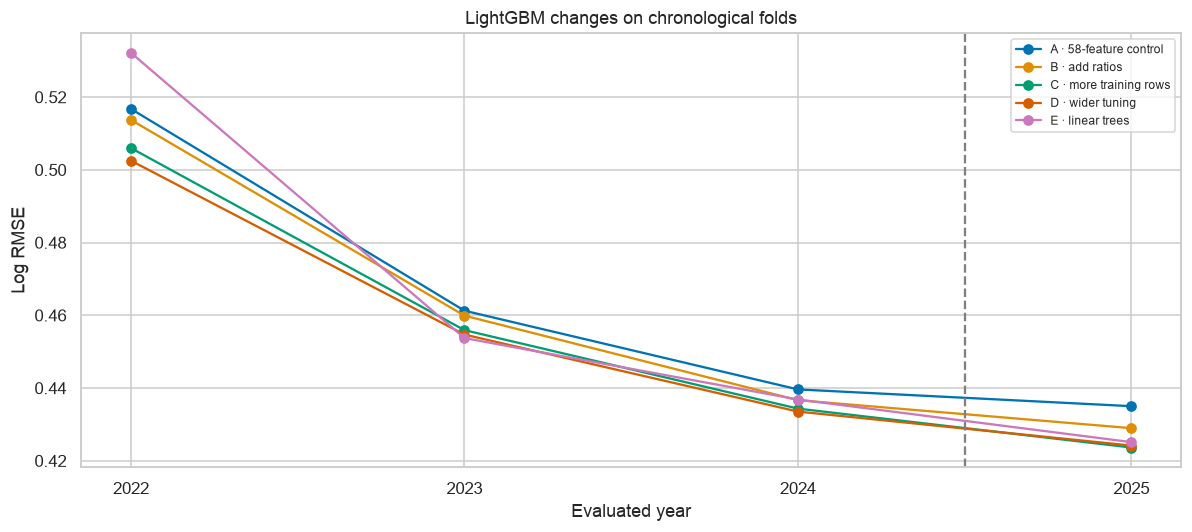

In [4]:
metrics = study(TUNING, 'candidate_metrics.csv')
annual = metrics.pivot(index='candidate', columns='test_year', values='rmse_log')
summary = metrics[metrics.test_year.isin(DEV)].groupby('candidate').agg(
    development_log_RMSE=('rmse_log', 'mean'), development_WAPE=('wape', 'mean'), development_bias=('aggregate_bias', 'mean'))
summary['2025_log_RMSE'] = annual[2025]
summary = summary.loc[[RIDGE, CONTROL, RATIOS, LARGE, TUNED, LINEAR]]
display(summary.rename(index=NAMES))
fig, ax = plt.subplots(figsize=(11, 5))
for candidate in [CONTROL, RATIOS, LARGE, TUNED, LINEAR]:
    ax.plot(annual.columns, annual.loc[candidate], marker='o', label=NAMES[candidate])
ax.axvline(2024.5, color='grey', linestyle='--')
ax.set(xticks=[2022, 2023, 2024, 2025], ylabel='Log RMSE', xlabel='Evaluated year', title='LightGBM changes on chronological folds')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## The three ratio features

$$x_1=\log\frac{1+A_{t-1}}{1+M_{20,t}},\quad
x_2=\log\frac{1+\bar A_{5,t}}{1+M_{20,t}},\quad
x_3=\log\frac{1+A_{t-1}}{1+M_{60,t}}.$$

Every input ends at the preceding stock row. The `+1` gives finite ratios when observed inputs are zero. Missing inputs remain missing until historical preprocessing. In a linear model, a log ratio can be represented by a difference between two log inputs. Explicit ratios let trees split directly on relative activity.

Adding ratios reduced development log RMSE by **0.00245** and improved every development year. Expanding the samples reduced it by another **0.00468**, the largest individual gain. Wider tuning added **0.00184**. That final step alone is below the 0.002 rule, while D's complete improvement over A clears it. D is selected by development point accuracy among the successful candidates. C has a slightly lower 2025 log RMSE, **0.42363 versus 0.42417**.

,2022,2023,2024,2025,mean_development_change
step,,,,,
B: + ratios,-0.0030,-0.0014,-0.0030,-0.0060,-0.0024
C: + more data,-0.0077,-0.0040,-0.0023,-0.0053,-0.0047
D: + wider tuning,-0.0035,-0.0012,-0.0008,0.0005,-0.0018
E: linear trees vs C,0.0262,-0.0022,0.0025,0.0015,0.0088
Overall: D vs control,-0.0142,-0.0066,-0.0061,-0.0108,-0.0090


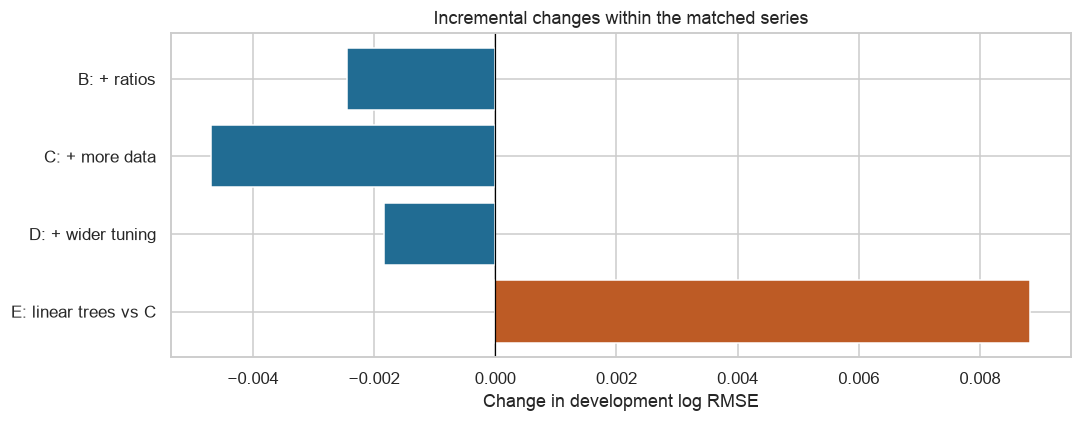

In [5]:
effects = study(TUNING, 'step_effects.csv')
display(effects.set_index('step'))
fig, ax = plt.subplots(figsize=(10, 4))
part = effects[~effects.step.str.startswith('Overall')]
ax.barh(part.step, part.mean_development_change, color=['#216c93' if value < 0 else '#bd5b25' for value in part.mean_development_change])
ax.axvline(0, color='black', linewidth=.8)
ax.set(xlabel='Change in development log RMSE', title='Incremental changes within the matched series')
ax.invert_yaxis()
plt.tight_layout(); plt.show()
# Recompute the recorded changes from the annual candidate table.
comparisons = [(RATIOS, CONTROL), (LARGE, RATIOS), (TUNED, LARGE), (LINEAR, LARGE), (TUNED, CONTROL)]
for row, (candidate, reference) in zip(effects.itertuples(index=False), comparisons):
    np.testing.assert_allclose(getattr(row, 'mean_development_change'),
                               (annual.loc[candidate, DEV] - annual.loc[reference, DEV]).mean(), atol=1e-12)

## Hyperparameters and their roles

| Setting | Why it matters |
| --- | --- |
| Learning rate | Scales each tree's contribution. Lower values generally require more trees |
| Number of leaves | Controls the number of fitted regions in each tree |
| Minimum observations per leaf | Limits small, highly specialised leaf fits |
| Row sampling and frequency | Fit trees on different historical row subsets |
| Feature sampling | Limit which columns a tree can use |
| L1 and L2 penalties | Regularise leaf outputs |
| Maximum histogram bins | Control split resolution and computational cost |
| Early stopping | Choose tree count from earlier validation performance |

The search below contains the eight configurations used for D, fixed across evaluated years. Each fold selects its own configuration and tree count. The validation year supplies both early stopping and configuration choice.

,objective,max_bin,reg_alpha,subsample_freq,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda
config_id,,,,,,,,,,
0,regression,127,0.1000,1,0.0500,63,300,0.8000,0.7000,5.0000
1,regression,127,0.1000,1,0.0500,127,500,0.8000,0.8500,10.0000
2,regression,127,0.1000,1,0.0500,255,1000,0.7000,0.7000,20.0000
3,regression,127,0.1000,1,0.0300,127,200,1.0000,0.6000,5.0000
4,regression,127,0.1000,1,0.0500,31,100,0.8000,0.8500,1.0000
5,regression,127,0.1000,1,0.0300,255,500,0.8000,0.8500,10.0000
6,regression,127,0.1000,1,0.0500,127,2000,0.9000,0.6000,1.0000
7,regression,127,0.1000,1,0.0300,63,1000,0.7000,0.8500,20.0000


,config_id,best_iteration,validation_rmse_log
test_year,,,
2022,0,671,0.5698
2023,3,782,0.5061
2024,3,959,0.4545
2025,3,519,0.4302


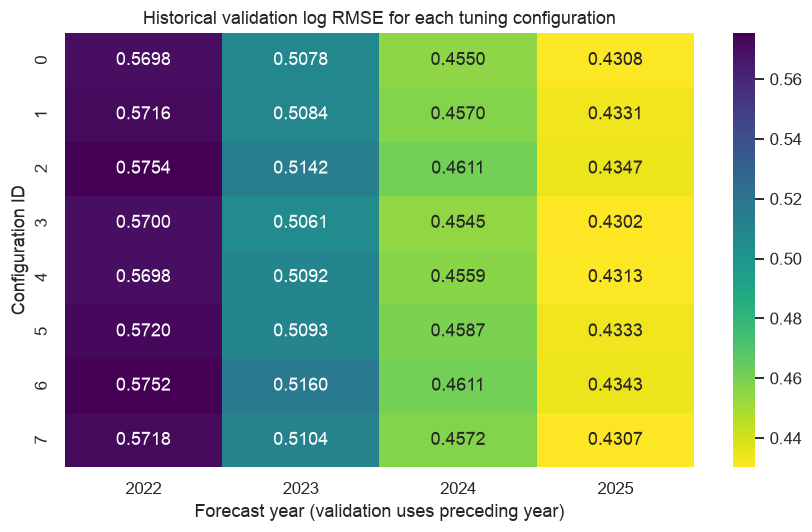

In [6]:
grid = study(TUNING, 'tuned_search_space.csv')
validation = study(TUNING, 'hyperparameter_validation.csv')
tuned_trials = validation[validation.candidate.eq(TUNED)].copy()
winners = tuned_trials.loc[tuned_trials.groupby('test_year').validation_rmse_log.idxmin()].sort_values('test_year')
display(grid.set_index('config_id'))
display(winners[['test_year', 'config_id', 'best_iteration', 'validation_rmse_log']].set_index('test_year'))
heat = tuned_trials.pivot(index='config_id', columns='test_year', values='validation_rmse_log')
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='viridis_r', ax=ax)
ax.set(title='Historical validation log RMSE for each tuning configuration', xlabel='Forecast year (validation uses preceding year)', ylabel='Configuration ID')
plt.tight_layout(); plt.show()
for row in winners.itertuples():
    result = metrics.query('candidate == @TUNED and test_year == @row.test_year').iloc[0]
    assert int(result.selected_config) == int(row.config_id)
    assert int(result.iterations) == max(25, int(row.best_iteration))

## Worked 2022 tuning and final refit

This section reruns the eight configurations using 750,000 tuning rows from 2016–2020 and 150,000 validation rows from 2021. It then refits the selected configuration on one million rows from 2017–2021 and scores every eligible 2022 stock-day. Configuration choice uses only the historical validation year.

The search reuses the shared feature loading, residual construction, preprocessing and bounds. The saved tuning run used LightGBM 4.7.0. The execution version is shown above. Historical reservoir sampling and runtime differences can change the selected tree count or score. This fresh worked result is excluded from the published comparison tables.

In [7]:
os.environ['AUCTION_DAILY_PANEL'] = str(PANEL)
from notebooks import challenger_utils as cu
assert not cu.SMOKE, 'Use full training budgets for this worked comparison.'
assert len(cu.RATIO_SET) == 61
print('Preparing historical tuning data.', flush=True)
tune = cu.load_period(2016, 2021, 750000, cu.SEED + 2022)
valid = cu.load_period(2021, 2022, 150000, cu.SEED + 100 + 2022)
x_tune, prep = fit_preprocessor(tune, cu.CONTINUOUS, cu.BOOLEAN, cu.CATEGORICAL)
x_valid = apply_preprocessor(valid, prep, cu.CONTINUOUS, cu.BOOLEAN, cu.CATEGORICAL)
z_tune, valid_base = cu.residual_target_and_base(tune, valid)
z_valid = valid.log1p_auction_volume.to_numpy(float) - valid_base
worked_trials = []
for configuration in grid.to_dict('records'):
    config_id = int(configuration.pop('config_id'))
    model = lgb.LGBMRegressor(n_estimators=3000, random_state=cu.SEED + 2022 + config_id,
                             n_jobs=6, deterministic=True, force_col_wise=True, verbosity=-1, **configuration)
    model.fit(x_tune, z_tune, eval_set=[(x_valid, z_valid)], eval_metric='rmse',
              callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
    predicted_log = cu.final_log_prediction(model.predict(x_valid), valid_base, tune.log1p_auction_volume.to_numpy(float))
    score = float(np.sqrt(np.mean((valid.log1p_auction_volume.to_numpy(float) - predicted_log)**2)))
    worked_trials.append({'config_id': config_id, 'best_iteration': int(model.best_iteration_), 'validation_log_RMSE': score})
    print(f'Configuration {config_id}: {model.best_iteration_} trees, validation log RMSE {score:.6f}', flush=True)
assert tune.date.max() < valid.date.min()
worked_trials = pd.DataFrame(worked_trials)
worked_best = worked_trials.loc[worked_trials.validation_log_RMSE.idxmin()]
display(worked_trials)
del tune, valid, x_tune, x_valid, model
_ = gc.collect()

Preparing historical tuning data.


Configuration 0: 754 trees, validation log RMSE 0.570240


Configuration 1: 555 trees, validation log RMSE 0.571905


Configuration 2: 747 trees, validation log RMSE 0.575795


Configuration 3: 1091 trees, validation log RMSE 0.570437


Configuration 4: 887 trees, validation log RMSE 0.568941


Configuration 5: 734 trees, validation log RMSE 0.572619


Configuration 6: 1252 trees, validation log RMSE 0.575160


Configuration 7: 1738 trees, validation log RMSE 0.572678


,config_id,best_iteration,validation_log_RMSE
0,0,754,0.5702
1,1,555,0.5719
2,2,747,0.5758
3,3,1091,0.5704
4,4,887,0.5689
5,5,734,0.5726
6,6,1252,0.5752
7,7,1738,0.5727


In [8]:
refit = cu.load_period(2017, 2022, 1000000, cu.SEED + 200 + 2022)
test = cu.load_period(2022, 2023)
x_refit, prep = fit_preprocessor(refit, cu.CONTINUOUS, cu.BOOLEAN, cu.CATEGORICAL)
x_test = apply_preprocessor(test, prep, cu.CONTINUOUS, cu.BOOLEAN, cu.CATEGORICAL)
z_refit, test_base = cu.residual_target_and_base(refit, test)
selected_config = grid.set_index('config_id').loc[int(worked_best.config_id)].to_dict()
model = lgb.LGBMRegressor(n_estimators=max(25, int(worked_best.best_iteration)), random_state=cu.SEED + 300 + 2022,
                         n_jobs=6, deterministic=True, force_col_wise=True, verbosity=-1, **selected_config)
model.fit(x_refit, z_refit)
residual = model.predict(x_test)
forecast_log = cu.final_log_prediction(residual, test_base, refit.log1p_auction_volume.to_numpy(float))
forecast = np.maximum(np.expm1(forecast_log), 0)
assert refit.date.max() < test.date.min()
assert np.isfinite(x_refit).all() and np.isfinite(x_test).all()
assert np.isfinite(forecast).all() and (forecast >= 0).all()
assert not test.duplicated(['date', 'permno']).any()
worked_result = forecast_metrics(test.auction_volume, forecast)
published_2022 = metrics.query('candidate == @TUNED and test_year == 2022').iloc[0]
display(pd.DataFrame({'fresh_2022_refit': worked_result,
                      'published_2022_tuned': {key: published_2022[key] for key in worked_result}}))
print(f'Historical validation selected configuration {int(worked_best.config_id)}. Final forecast covers {len(test):,} 2022 stock-days.')
# Serialise and reload the worked fit in temporary storage to check reconstruction.
model_path = Path(work.name) / 'worked_2022_lightgbm.txt'
model.booster_.save_model(str(model_path))
reloaded = lgb.Booster(model_file=str(model_path))
np.testing.assert_allclose(reloaded.predict(x_test[:2000], num_threads=6), residual[:2000], rtol=1e-12, atol=1e-12)
del refit, test, x_refit, x_test, model, reloaded
cu.con.close()
_ = gc.collect()

,fresh_2022_refit,published_2022_tuned
observations,"328,634.0000","328,634.0000"
mae_raw,"70,091.6855","70,012.1614"
wape,0.3602,0.3598
mae_log,0.3498,0.3502
rmse_log,0.5045,0.5025
spearman,0.9546,0.9548
aggregate_bias,-0.1629,-0.1475


Historical validation selected configuration 4. Final forecast covers 328,634 2022 stock-days.


The fresh 2022 run selected **configuration 4 with 887 trees**, compared with the published fold's **configuration 0 with 671 trees**. Its test log RMSE was **0.5045**, against **0.5025** in the saved study. The notebook executed with LightGBM 4.6.0 and fresh historical reservoir samples, while the original study recorded 4.7.0. This result demonstrates sensitivity of the selected configuration and is retained as a worked refit alongside the published four-year experiment. It does not update the saved model ranking.

## Linear trees and the adoption decision

Linear trees fit a regularised linear model inside each leaf. The experiment tried 31 and 63 leaves with `linear_lambda=1`. It used C's large training tier and ratio features. Development log RMSE worsened from **0.46541 to 0.47424**, driven by a large 2022 deterioration. It also failed the paired log-MAE condition against the frozen ridge.

The recorded gate below compares candidates against the matched A control and the frozen ridge within the 16a series. We reconstruct its numerical thresholds and boolean decisions from the saved annual metrics and paired intervals.

In [9]:
selection = study(TUNING, 'candidate_selection.csv')
evaluated = selection[selection.candidate.ne(selection.reference)].copy()
for entry in evaluated.itertuples():
    expected_change = annual.loc[entry.candidate, DEV].mean() - annual.loc[entry.reference, DEV].mean()
    expected_worst = (annual.loc[entry.candidate, DEV] - annual.loc[entry.reference, DEV]).max()
    np.testing.assert_allclose(entry.rmse_change_vs_reference, expected_change, atol=1e-12)
    np.testing.assert_allclose(entry.worst_year_change, expected_worst, atol=1e-12)
    expected_gate = (expected_change <= -.002) and (expected_worst <= .002) and (entry.log_mae_ci_97_5 < 0)
    assert bool(entry.passes_gate) == expected_gate
columns = ['candidate', 'reference', 'rmse_change_vs_reference', 'worst_year_change',
           'log_mae_ci_97_5', 'passes_gate']
display(evaluated[columns].assign(candidate=lambda d: d.candidate.map(NAMES), reference=lambda d: d.reference.map(NAMES)))

,candidate,reference,rmse_change_vs_reference,worst_year_change,log_mae_ci_97_5,passes_gate
0,A · 58-feature control,Frozen ridge,-0.0153,-0.0064,-0.0021,True
1,B · add ratios,Frozen ridge,-0.0178,-0.0094,-0.0044,True
2,C · more training rows,Frozen ridge,-0.0225,-0.0117,-0.0056,True
3,D · wider tuning,Frozen ridge,-0.0243,-0.0125,-0.0075,True
4,E · linear trees,Frozen ridge,-0.0136,-0.0016,0.0065,False
6,B · add ratios,A · 58-feature control,-0.0024,-0.0014,-0.0018,True
7,C · more training rows,A · 58-feature control,-0.0071,-0.0053,-0.0021,True
8,D · wider tuning,A · 58-feature control,-0.0090,-0.0061,-0.0044,True
9,E · linear trees,A · 58-feature control,0.0017,0.0154,0.0106,False


The saved paired intervals resample whole dates independently, with 2,000 replicates, and measure mean daily log-MAE differences. They retain each date's cross-section together. Despite the original “date_block” filenames, this is single-date resampling and does not preserve serial dependence between adjacent dates. The intervals condition on fitted forecasts and omit refitting and accumulated research-selection uncertainty.

## Which inputs did the tuned model use?

Split gain records the fitted training loss reduction attributed to a source feature, aggregated across its encoded columns and missing indicators. It helps describe the model and can be divided among correlated substitutes. It does not estimate causal importance or guarantee the same ranking in a future period.

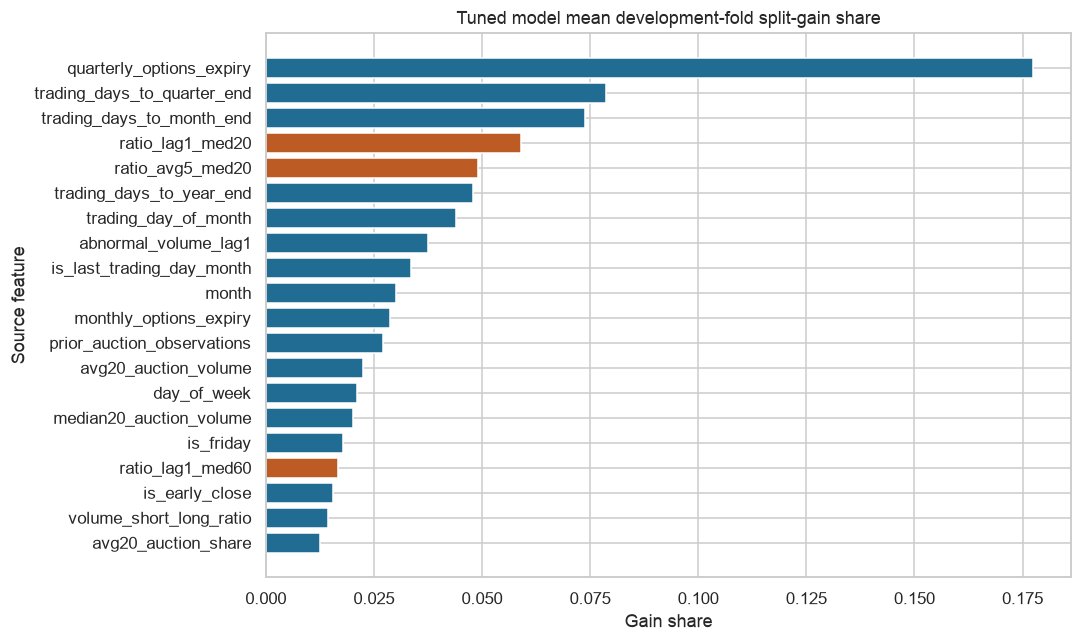

,mean_gain_share
source_feature,
quarterly_options_expiry,0.1774
trading_days_to_quarter_end,0.0786
trading_days_to_month_end,0.0737
ratio_lag1_med20,0.0590
ratio_avg5_med20,0.0492
trading_days_to_year_end,0.0479
trading_day_of_month,0.0440
abnormal_volume_lag1,0.0376
is_last_trading_day_month,0.0336


In [10]:
importance = study(TUNING, 'feature_importance.csv')
top = (importance[importance.candidate.eq(TUNED) & importance.test_year.isin(DEV)]
       .groupby('source_feature').gain_share.mean().sort_values(ascending=False).head(20))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index[::-1], top.values[::-1],
        color=['#bd5b25' if name.startswith('ratio_') else '#216c93' for name in top.index[::-1]])
ax.set(title='Tuned model mean development-fold split-gain share', xlabel='Gain share', ylabel='Source feature')
plt.tight_layout(); plt.show()
display(top.rename('mean_gain_share').to_frame())

## Remaining weaknesses

The verified compact study retained segment and tail diagnostics. The table below shows its development results on large actual auctions and calendar groups. Actual-volume tail membership is known after the auction and is used only for evaluation. These diagnostics refer to the earlier compact model, because the tuning series did not save the same segment table. They should not be relabelled as tuned-model subgroup results.

In [11]:
segment = study(VERIFIED, 'nonlinear_segment_diagnostics.csv')
segment = segment[segment.candidate.isin([RIDGE, 'lgbm_residual_58_l2']) & segment.dimension.isin(['actual_tail', 'event'])]
display(segment.set_index(['dimension', 'segment', 'candidate'])[['observations', 'rmse_log', 'wape', 'aggregate_bias']])
recommendation = json.loads((TUNING / 'recommendation.json').read_text())
assert recommendation['best_development_candidate'] == TUNED
np.testing.assert_allclose(summary.loc[TUNED, 'development_log_RMSE'], recommendation['best_development_rmse_log'], atol=1e-12)

observations  \
dimension   segment          candidate                                                    
actual_tail lower_99pct      rolling5_residual_auction_calendar_liquidity        953888   
            top_1pct         rolling5_residual_auction_calendar_liquidity          9637   
event       monthly_expiry   rolling5_residual_auction_calendar_liquidity         30713   
            regular          rolling5_residual_auction_calendar_liquidity        871142   
            month_end        rolling5_residual_auction_calendar_liquidity         46239   
            quarterly_expiry rolling5_residual_auction_calendar_liquidity         15431   
actual_tail lower_99pct      lgbm_residual_58_l2                                 953888   
            top_1pct         lgbm_residual_58_l2                                   9637   
event       monthly_expiry   lgbm_residual_58_l2                                  30713   
            regular          lgbm_residual_58_l2                                 871142   
            quarterly_expiry lgbm_residual_58_l2                                  15431   
            month_end        lgbm_residual_58_l2                                  46239   

                                                                           rmse_log  \
dimension   segment          candidate                                                
actual_tail lower_99pct      rolling5_residual_auction_calendar_liquidity    0.4737   
            top_1pct         rolling5_residual_auction_calendar_liquidity    1.3219   
event       monthly_expiry   rolling5_residual_auction_calendar_liquidity    0.5436   
            regular          rolling5_residual_auction_calendar_liquidity    0.4670   
            month_end        rolling5_residual_auction_calendar_liquidity    0.6862   
            quarterly_expiry rolling5_residual_auction_calendar_liquidity    0.8078   
actual_tail lower_99pct      lgbm_residual_58_l2                             0.4590   
            top_1pct         lgbm_residual_58_l2                             1.1463   
event       monthly_expiry   lgbm_residual_58_l2                             0.5458   
            regular          lgbm_residual_58_l2                             0.4489   
            quarterly_expiry lgbm_residual_58_l2                             0.7679   
            month_end        lgbm_residual_58_l2                             0.6559   

                                                                            wape  \
dimension   segment          candidate                                             
actual_tail lower_99pct      rolling5_residual_auction_calendar_liquidity 0.3168   
            top_1pct         rolling5_residual_auction_calendar_liquidity 0.5513   
event       monthly_expiry   rolling5_residual_auction_calendar_liquidity 0.3812   
            regular          rolling5_residual_auction_calendar_liquidity 0.3239   
            month_end        rolling5_residual_auction_calendar_liquidity 0.5024   
            quarterly_expiry rolling5_residual_auction_calendar_liquidity 0.5485   
actual_tail lower_99pct      lgbm_residual_58_l2                          0.3066   
            top_1pct         lgbm_residual_58_l2                          0.5271   
event       monthly_expiry   lgbm_residual_58_l2                          0.3833   
            regular          lgbm_residual_58_l2                          0.3134   
            quarterly_expiry lgbm_residual_58_l2                          0.5283   
            month_end        lgbm_residual_58_l2                          0.4703   

                                                                           aggregate_bias  
dimension   segment          candidate                                                     
actual_tail lower_99pct      rolling5_residual_auction_calendar_liquidity         -0.0655  
            top_1pct         rolling5_residual_auction_calendar_liquidity         -0.4325  
event       monthly_expiry   rolling

## Checkpoint 3 decision

Carry forward **`lgbm_61_ratios_large_tuned`** as the selected daily LightGBM. Its 2022–2024 development log RMSE is **0.46357**, compared with **0.48788** for the frozen ridge reference in this matched series, and its WAPE is **34.88%**. Its 2025 log RMSE is **0.42417**.

Relative to the matched 58-feature tree control, the full change improves development log RMSE by **0.00897**. Larger training samples supplied the largest step. Ratios helped consistently, while linear trees worsened development performance. Wider tuning supplied a smaller incremental improvement, with the untuned large-tier model slightly ahead on the previously inspected 2025 period.

The notebook's fresh worked tuning run is presented alongside its published 2022 counterpart, with runtime and sampling differences disclosed. The saved compact model reconstruction, search-selection checks, step arithmetic and replacement-gate checks verify the evidence shown here.

The next stage is notebook 06, comparing tuned CatBoost and XGBoost with the LightGBM reference.

## Source map

| Evidence | Source relative to the repository root |
| --- | --- |
| Historical broad LightGBM comparison | `outputs/eda/16_nonlinear_challengers` |
| Reconciled reference and documented discrepancy | `outputs/reproduction/02_benchmark_reconciliation` |
| Compact models, preprocessing and verified metrics | `outputs/reproduction/03_compact_nonlinear` |
| Ratio, sample-size, tuning and linear-tree experiments | `outputs/eda/16a_lightgbm_improvements` |
| Fitting and preprocessing recipes | `notebooks/challenger_utils.py`, `notebooks/modeling_utils.py`, `notebooks/build_notebook_16a.py` |

The numerical summaries display complete saved studies. Original row-level 16a prediction files are absent in this checkout, so its published scores are verified for table arithmetic and decision consistency. The original compact saved models supply the direct forecast reconstruction checks. The worked tuning run supplies an executable example of the large-tier procedure.

In [12]:
assert len(reconstructed) == 20 and reconstructed.verified.all()
assert int(reconstructed.groupby('year').observations.first().sum()) == 1271378
assert len(worked_trials) == 8 and worked_result['observations'] == 328634
assert len(evaluated) == 9
print('Checkpoint 3 verified: 20 compact model-year comparisons, 8 fresh tuning trials, a complete 2022 refit, saved-model reload, and reconstructed step/gate decisions.')
con.close()
work.cleanup()

Checkpoint 3 verified: 20 compact model-year comparisons, 8 fresh tuning trials, a complete 2022 refit, saved-model reload, and reconstructed step/gate decisions.
